# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Бессараб Марія  
**Група:** 4.9  
**Дата:** 20.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report

tf.keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train: (60000, 28, 28)
y_train: (60000,)
x_test: (10000, 28, 28)
y_test: (10000,)


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

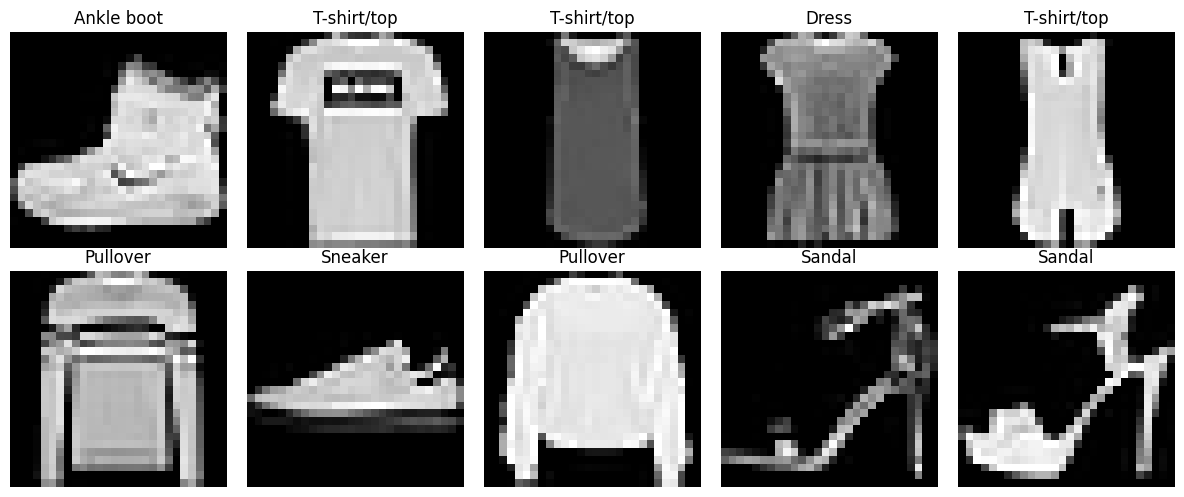

In [3]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("x_train:", x_train.dtype, "min =", x_train.min(), "max =", x_train.max())
print("x_test:", x_test.dtype, "min =", x_test.min(), "max =", x_test.max())

x_train: float32 min = 0.0 max = 1.0
x_test: float32 min = 0.0 max = 1.0


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
# Створіть і скомпілюйте модель.
# Ваш код:
model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

**Пояснення вибору гіперпараметрів:**

- **Кількість нейронів (256 → 128).** Вхідний вектор після Flatten має 784 ознаки, тому перший прихований шар із 256 нейронів достатньо великий, щоб виділити різноманітні ознаки форми й текстури одягу, а другий шар зі 128 нейронів поступово стискає представлення перед вихідним шаром із 10 класами. Така архітектура має близько 235 тис. параметрів, що достатньо для досягнення точності вище 0,87 і водночас не надто схильне до перенавчання.
- **Dropout (0,3 та 0,2).** Під час навчання випадково вимикається 30 % нейронів першого шару і 20 % — другого. Це зменшує перенавчання (модель не «запам'ятовує» навчальні приклади), а менше значення для другого шару пов'язане з тим, що він уже менший за розміром.
- **Швидкість навчання (0,001).** Це стандартне значення для оптимізатора Adam: воно забезпечує стабільне й досить швидке зменшення функції втрат. Більші значення (0,01) можуть спричиняти коливання loss, менші (0,0001) — надто повільну збіжність. Додатково ReduceLROnPlateau зменшує швидкість навчання вдвічі, коли валідаційні втрати перестають зменшуватися.

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1)

history = model.fit(x_train, y_train,
                    epochs=50,
                    batch_size=64,
                    validation_split=0.1,
                    callbacks=[early_stopping, reduce_lr],
                    verbose=2)

epochs_1 = len(history.history['loss'])
print("Кількість епох навчання:", epochs_1)

Epoch 1/50
844/844 - 4s - 5ms/step - accuracy: 0.7926 - loss: 0.5777 - val_accuracy: 0.8368 - val_loss: 0.4394 - learning_rate: 0.0010
Epoch 2/50
844/844 - 3s - 4ms/step - accuracy: 0.8447 - loss: 0.4264 - val_accuracy: 0.8538 - val_loss: 0.3888 - learning_rate: 0.0010
Epoch 3/50
844/844 - 4s - 4ms/step - accuracy: 0.8585 - loss: 0.3883 - val_accuracy: 0.8620 - val_loss: 0.3702 - learning_rate: 0.0010
Epoch 4/50
844/844 - 3s - 4ms/step - accuracy: 0.8652 - loss: 0.3652 - val_accuracy: 0.8687 - val_loss: 0.3615 - learning_rate: 0.0010
Epoch 5/50
844/844 - 3s - 4ms/step - accuracy: 0.8717 - loss: 0.3493 - val_accuracy: 0.8767 - val_loss: 0.3393 - learning_rate: 0.0010
Epoch 6/50
844/844 - 3s - 4ms/step - accuracy: 0.8748 - loss: 0.3358 - val_accuracy: 0.8755 - val_loss: 0.3371 - learning_rate: 0.0010
Epoch 7/50
844/844 - 3s - 4ms/step - accuracy: 0.8801 - loss: 0.3252 - val_accuracy: 0.8768 - val_loss: 0.3363 - learning_rate: 0.0010
Epoch 8/50
844/844 - 3s - 4ms/step - accuracy: 0.8813 -

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
# Виведіть підсумок архітектури моделі.
# Ваш код:
model.summary()
print("Кількість шарів:", len(model.layers))
print("Загальна кількість параметрів:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

Кількість шарів: 6
Загальна кількість параметрів: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:
import os

model.save('fashion_mnist_model.keras')
print("Модель збережено:", os.path.abspath('fashion_mnist_model.keras'))
print("Розмір файлу:", round(os.path.getsize('fashion_mnist_model.keras') / 1024, 1), "КБ")

Модель збережено: /content/fashion_mnist_model.keras
Розмір файлу: 2786.9 КБ


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

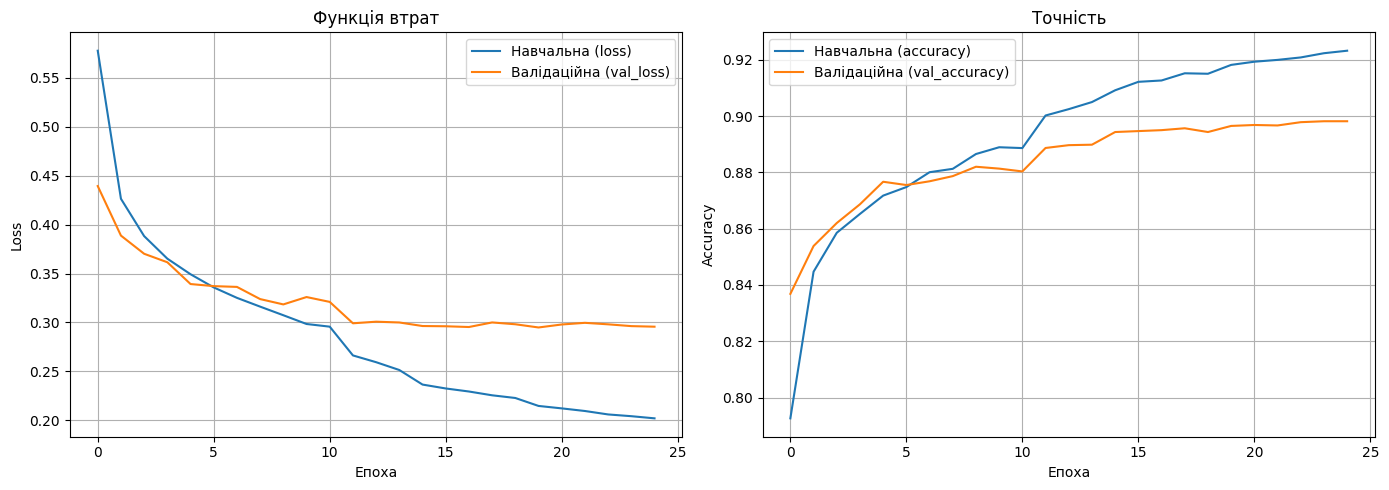

In [9]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Навчальна (loss)')
plt.plot(history.history['val_loss'], label='Валідаційна (val_loss)')
plt.title('Функція втрат')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Навчальна (accuracy)')
plt.plot(history.history['val_accuracy'], label='Валідаційна (val_accuracy)')
plt.title('Точність')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [10]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")
print("Поріг 0.87 досягнуто" if test_acc >= 0.87 else "Поріг 0.87 не досягнуто")

y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)
print()
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

errors_per_class = np.bincount(y_test[y_pred != y_test], minlength=10)
print("Кількість помилок за класами:")
for name, err in sorted(zip(class_names, errors_per_class), key=lambda x: -x[1]):
    print(f"{name}: {err}")

Test loss: 0.3091
Test accuracy: 0.8957
Поріг 0.87 досягнуто

              precision    recall  f1-score   support

 T-shirt/top     0.8328    0.8520    0.8423      1000
     Trouser     0.9929    0.9730    0.9828      1000
    Pullover     0.8266    0.8010    0.8136      1000
       Dress     0.8935    0.9060    0.8997      1000
        Coat     0.8112    0.8380    0.8244      1000
      Sandal     0.9808    0.9710    0.9759      1000
       Shirt     0.7243    0.7040    0.7140      1000
     Sneaker     0.9429    0.9750    0.9587      1000
         Bag     0.9761    0.9810    0.9786      1000
  Ankle boot     0.9755    0.9560    0.9657      1000

    accuracy                         0.8957     10000
   macro avg     0.8957    0.8957    0.8956     10000
weighted avg     0.8957    0.8957    0.8956     10000

Кількість помилок за класами:
Shirt: 296
Pullover: 199
Coat: 162
T-shirt/top: 148
Dress: 94
Ankle boot: 44
Sandal: 29
Trouser: 27
Sneaker: 25
Bag: 19


### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

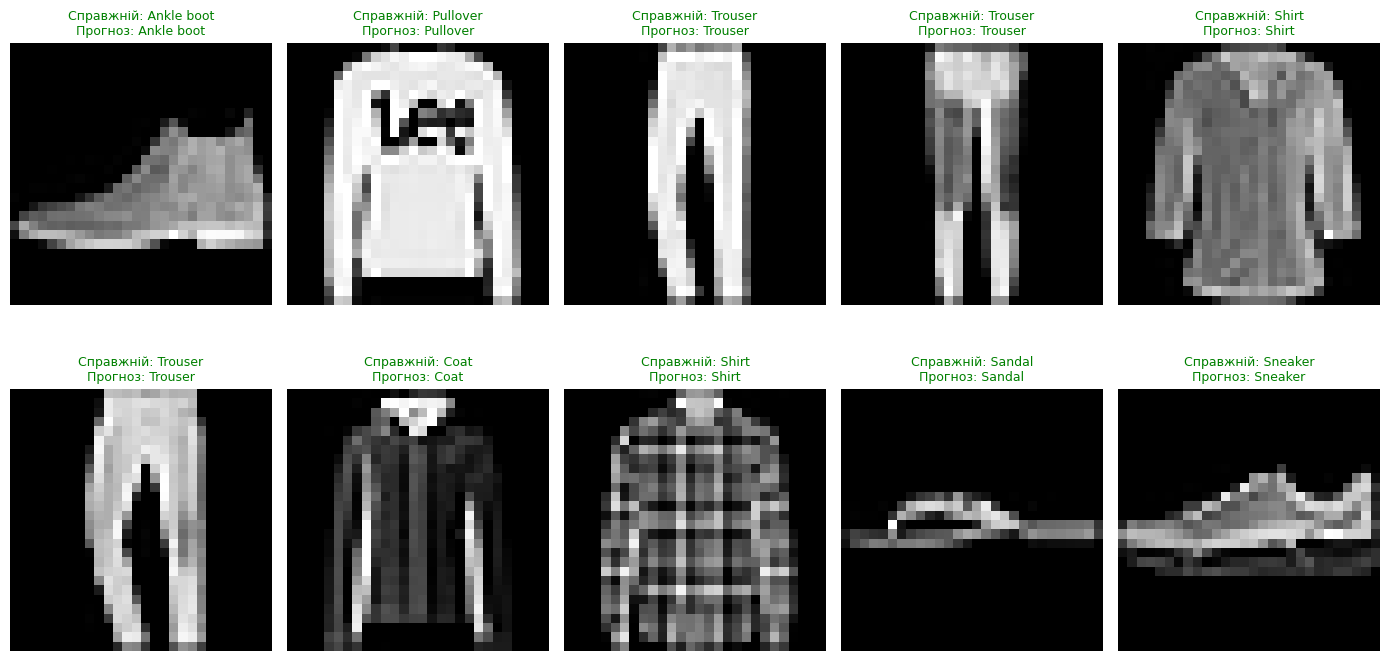

In [18]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
plt.figure(figsize=(14, 7.5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    color = 'green' if y_pred[i] == y_test[i] else 'red'
    plt.title(f"Справжній: {class_names[y_test[i]]}\nПрогноз: {class_names[y_pred[i]]}", color=color, fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
Модель із завдання 1 на тестовій вибірці отримала **accuracy = 0,8957** (loss = 0,3091). Навчання зупинилося на 25-й епосі завдяки EarlyStopping (з відновленням найкращих ваг), а ReduceLROnPlateau кілька разів зменшував швидкість навчання. Різниця між навчальною (≈0,92) та валідаційною (≈0,90) точністю невелика, тобто Dropout стримує перенавчання.

Найбільше помилок модель робить на класах верхнього одягу зі схожим силуетом:
- **Shirt** — 296 помилок (recall 0,704, F1 = 0,714) — найскладніший клас;
- **Pullover** — 199 помилок (F1 = 0,814);
- **Coat** — 162 помилки (F1 = 0,824);
- **T-shirt/top** — 148 помилок (F1 = 0,842).

Ці класи на зображеннях 28 × 28 відрізняються лише дрібними деталями (комір, ґудзики, довжина рукава), тому модель часто плутає їх між собою. Найкраще розпізнаються класи з характерною формою: Trouser (F1 = 0,983), Bag (0,979), Sandal (0,976), Ankle boot (0,966), Sneaker (0,959).

Вимогу щодо мінімальної точності **виконано**: 0,8957 > 0,87.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [19]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
!pip install -q keras-tuner

import keras_tuner as kt
from keras_tuner import RandomSearch
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2

print("Keras Tuner:", kt.__version__)

Keras Tuner: 1.4.8


### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [20]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:
from sklearn.model_selection import train_test_split

x_tr, x_val, y_tr, y_val = train_test_split(x_train, y_train,
                                            test_size=0.1,
                                            random_state=42,
                                            stratify=y_train)

print("Навчальна:", x_tr.shape, y_tr.shape)
print("Валідаційна:", x_val.shape, y_val.shape)
print("Тестова:", x_test.shape, y_test.shape)
print("Діапазон значень:", x_tr.min(), "-", x_tr.max())

Навчальна: (54000, 28, 28) (54000,)
Валідаційна: (6000, 28, 28) (6000,)
Тестова: (10000, 28, 28) (10000,)
Діапазон значень: 0.0 - 1.0


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [21]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:
def build_model(hp):
    model = keras.Sequential()
    model.add(keras.Input(shape=(28, 28)))
    model.add(Flatten())
    for i in range(hp.Int('num_layers', min_value=1, max_value=3)):
        model.add(Dense(units=hp.Int(f'units_{i}', min_value=32, max_value=512, step=32),
                        activation='relu',
                        kernel_regularizer=l2(0.0001)))
        model.add(Dropout(0.2))
    model.add(Dense(10, activation='softmax'))

    model.compile(optimizer=keras.optimizers.Adam(
                      learning_rate=hp.Choice('learning_rate', values=[0.01, 0.001, 0.0001])),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [22]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner = RandomSearch(build_model,
                     objective='val_accuracy',
                     max_trials=3,
                     executions_per_trial=1,
                     directory='keras_tuner_dir',
                     project_name='fashion_mnist_tuning',
                     seed=42,
                     overwrite=True)

tuner.search_space_summary()

Search space summary
Default search space size: 3
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [23]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:
tuner.search(x_tr, y_tr,
             epochs=20,
             batch_size=64,
             validation_data=(x_val, y_val),
             callbacks=[EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
                        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5)],
             verbose=2)

tuner.results_summary()

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Найкращі гіперпараметри:")
print("Кількість прихованих шарів:", best_hp.get('num_layers'))
for i in range(best_hp.get('num_layers')):
    print(f"Нейронів у шарі {i + 1}:", best_hp.get(f'units_{i}'))
print("Швидкість навчання:", best_hp.get('learning_rate'))

best_model = tuner.hypermodel.build(best_hp)
best_model.summary()

history_tuned = best_model.fit(x_tr, y_tr,
                               epochs=50,
                               batch_size=64,
                               validation_data=(x_val, y_val),
                               callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
                                          ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1)],
                               verbose=2)

epochs_2 = len(history_tuned.history['loss'])
print("Кількість епох навчання:", epochs_2)

Trial 3 Complete [00h 01m 06s]
val_accuracy: 0.8838333487510681

Best val_accuracy So Far: 0.8988333344459534
Total elapsed time: 00h 03m 15s
Results summary
Results in keras_tuner_dir/fashion_mnist_tuning
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 1 summary
Hyperparameters:
num_layers: 1
units_0: 480
learning_rate: 0.001
units_1: 288
Score: 0.8988333344459534

Trial 2 summary
Hyperparameters:
num_layers: 1
units_0: 256
learning_rate: 0.01
units_1: 512
Score: 0.8838333487510681

Trial 0 summary
Hyperparameters:
num_layers: 2
units_0: 32
learning_rate: 0.001
units_1: 32
Score: 0.8824999928474426
Найкращі гіперпараметри:
Кількість прихованих шарів: 1
Нейронів у шарі 1: 480
Швидкість навчання: 0.001


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 480)            │       376,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         4,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 381,610 (1.46 MB)

 Trainable params: 381,610 (1.46 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
844/844 - 5s - 6ms/step - accuracy: 0.8137 - loss: 0.5778 - val_accuracy: 0.8415 - val_loss: 0.4777 - learning_rate: 0.0010
Epoch 2/50
844/844 - 4s - 5ms/step - accuracy: 0.8555 - loss: 0.4530 - val_accuracy: 0.8552 - val_loss: 0.4399 - learning_rate: 0.0010
Epoch 3/50
844/844 - 4s - 5ms/step - accuracy: 0.8660 - loss: 0.4241 - val_accuracy: 0.8707 - val_loss: 0.4114 - learning_rate: 0.0010
Epoch 4/50
844/844 - 5s - 6ms/step - accuracy: 0.8720 - loss: 0.4066 - val_accuracy: 0.8700 - val_loss: 0.4104 - learning_rate: 0.0010
Epoch 5/50
844/844 - 4s - 5ms/step - accuracy: 0.8766 - loss: 0.3945 - val_accuracy: 0.8815 - val_loss: 0.3937 - learning_rate: 0.0010
Epoch 6/50
844/844 - 4s - 5ms/step - accuracy: 0.8799 - loss: 0.3850 - val_accuracy: 0.8758 - val_loss: 0.3999 - learning_rate: 0.0010
Epoch 7/50
844/844 - 5s - 5ms/step - accuracy: 0.8813 - loss: 0.3816 - val_accuracy: 0.8810 - val_loss: 0.3924 - learning_rate: 0.0010
Epoch 8/50
844/844 - 4s - 5ms/step - accuracy: 0.8845 -

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Test loss: 0.3376
Test accuracy: 0.9019

              precision    recall  f1-score   support

 T-shirt/top     0.8508    0.8610    0.8559      1000
     Trouser     0.9939    0.9760    0.9849      1000
    Pullover     0.8180    0.8360    0.8269      1000
       Dress     0.8946    0.9170    0.9057      1000
        Coat     0.8310    0.8260    0.8285      1000
      Sandal     0.9828    0.9700    0.9763      1000
       Shirt     0.7513    0.7250    0.7379      1000
     Sneaker     0.9517    0.9650    0.9583      1000
         Bag     0.9779    0.9730    0.9754      1000
  Ankle boot     0.9661    0.9700    0.9681      1000

    accuracy                         0.9019     10000
   macro avg     0.9018    0.9019    0.9018     10000
weighted avg     0.9018    0.9019    0.9018     10000



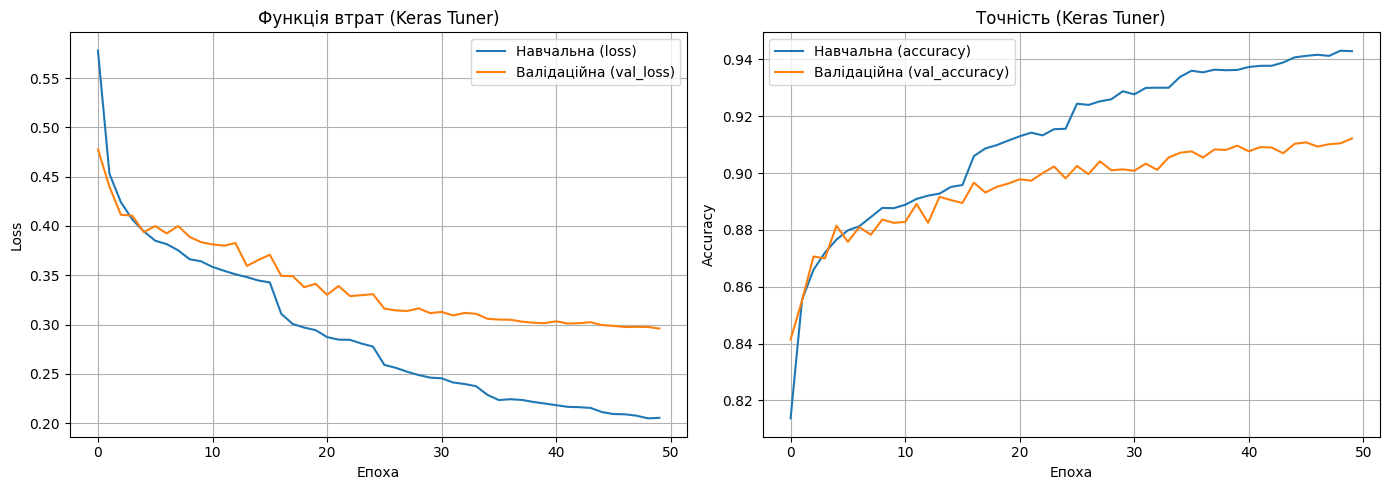

Модель із завдання 1: accuracy = 0.8957, loss = 0.3091, епох = 25
Модель після Keras Tuner: accuracy = 0.9019, loss = 0.3376, епох = 50


In [24]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:
test_loss_2, test_acc_2 = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss_2:.4f}")
print(f"Test accuracy: {test_acc_2:.4f}")

y_pred_2 = np.argmax(best_model.predict(x_test, verbose=0), axis=1)
print()
print(classification_report(y_test, y_pred_2, target_names=class_names, digits=4))

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_tuned.history['loss'], label='Навчальна (loss)')
plt.plot(history_tuned.history['val_loss'], label='Валідаційна (val_loss)')
plt.title('Функція втрат (Keras Tuner)')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_tuned.history['accuracy'], label='Навчальна (accuracy)')
plt.plot(history_tuned.history['val_accuracy'], label='Валідаційна (val_accuracy)')
plt.title('Точність (Keras Tuner)')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print(f"Модель із завдання 1: accuracy = {test_acc:.4f}, loss = {test_loss:.4f}, епох = {epochs_1}")
print(f"Модель після Keras Tuner: accuracy = {test_acc_2:.4f}, loss = {test_loss_2:.4f}, епох = {epochs_2}")

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 | 1 |
| Кількість нейронів | 256 і 128 | 480 |
| Швидкість навчання | 0,001 (+ ReduceLROnPlateau) | 0,001 (+ ReduceLROnPlateau) |
| Точність на тестовій вибірці (accuracy) | 0,8957 | 0,9019 |
| Втрати на тестовій вибірці (loss) | 0,3091 | 0,3376 |
| Кількість епох навчання | 25 | 50 |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
1. **Так.** У завданні 1 отримано тестову точність 0,8957, що перевищує поріг 0,87.
2. **Так, але помірно.** Після Keras Tuner тестова точність зросла з 0,8957 до 0,9019 (приблизно на 0,6 процентного пункта). Тестовий loss кращої моделі трохи вищий (0,3376 проти 0,3091), але його не можна порівнювати напряму: для моделі з Keras Tuner у значення втрат додається штраф L2-регуляризації. Крім того, вона навчалася всі 50 епох, бо валідаційні втрати продовжували повільно зменшуватися. Під час пошуку було перевірено лише 3 конфігурації, тому простір гіперпараметрів досліджено дуже обмежено.
3. **Найкращою виявилася конфігурація з 1 прихованим шаром на 480 нейронів і швидкістю навчання 0,001** (val_accuracy = 0,8988 під час пошуку). Конфігурація 2 × 32 нейрони дала лише 0,8825 через недостатню ємність мережі, а 256 нейронів зі швидкістю навчання 0,01 — 0,8838, бо надто великий крок оптимізації спричиняє нестабільне навчання. Результати можуть відрізнятися між запусками через випадкову ініціалізацію ваг, випадкові маски Dropout, перемішування даних у батчах, випадковий вибір комбінацій у RandomSearch (лише 3 спроби з дуже великої кількості можливих), різний момент спрацювання EarlyStopping і недетермінованість обчислень на CPU/GPU.
4. **Найскладніше класифікувати Shirt** (F1 = 0,714 / 0,738 для двох моделей), а також **Pullover** (0,814 / 0,827), **Coat** (0,824 / 0,829) і **T-shirt/top** (0,842 / 0,856). Ці класи мають схожий силует і відрізняються дрібними деталями, які погано помітні на зображеннях 28 × 28. Найлегше розпізнаються Trouser, Bag, Sandal, Sneaker та Ankle boot.

Загалом обидві моделі задовольняють вимогу щодо точності; автоматизований добір гіперпараметрів підтвердив, що для Fashion MNIST оптимальна швидкість навчання Adam становить 0,001, а подальше підвищення точності повнозв’язної мережі обмежене — для суттєвого покращення доцільно використовувати згорткові нейронні мережі.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.